# Case Seguradora Horizonte — Anexo técnico

## Score do prompt × ML na sindicância Auto, ponto de corte e valor das iniciativas prioritárias

## Leia primeiro

Por que este notebook existe: O case pede uma única opção técnica. Escolhi um
notebook porque as decisões mais difíceis de defender na arguição são numéricas:
as iniciativas prioritárias se pagam? Usar o score do prompt ou o modelo de ML?
Quantos casos mandar para a sindicância? Sem acesso aos dados da Horizonte, o
caminho honesto é simular um mundo com as características do enunciado e mostrar
o método de decisão, que é o mesmo que seria aplicado aos dados reais.

Respostas curtas (o grau de confiança de cada uma está na Parte 8):

| \# | Pergunta                               | Resposta                                                                                                                                                                                                                                                                           | Parte |
| -- | -------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----- |
| 1  | A pré-análise Auto D0 se paga?         | No caso base, a capacidade liberada vale **\~R$ 3,6 mi/ano** contra **~R$ 1,9 mi/ano** de custo. Mas isso só vira resultado se **pelo menos 52% da capacidade virar caixa** (ou valor equivalente) e se o pagamento indevido adicional do fluxo direto ficar abaixo de **\~0,2%**. | 1     |
| 2  | Score do prompt ou ML?                 | O que mais pesa são as **variáveis novas** (+28 pp de precisão). O prompt **sozinho** é pior que o modelo atual. **Como variável do ML**, acrescenta \~2 pp, e **só se** trouxer informação que os dados estruturados não têm. É uma hipótese a testar, não uma conclusão.         | 3     |
| 3  | Quantos casos enviar à sindicância?    | Com o modelo novo, **a capacidade de 600/mês é o gargalo**: os últimos casos enviados ainda acertam \~28%, e o equilíbrio é 15,7%. Cada +100 casos/mês renderia **\~R$ 44 mil/mês líquidos**.                                                                                      | 4     |
| 3b | E trocar o modelo, com a mesma equipe? | Vale mais: **dobra as confirmações**, **\~R$ 10 mi/ano nas premissas** e **~R$ 2,5 mi mesmo com metade do ganho e metade da perda evitada**. Por isso a sindicância v2 é **co-prioridade 1**, começando por um teste no histórico.                                                 | 4     |
| 4  | Dá para medir isso na vida real?       | **Precisão, sim**: mede-se diretamente nos casos investigados. **Recall, só com auditoria por sorteio**: com 60 casos/mês ela corrige o viés grosseiro, mas não tem precisão para comparar modelos parecidos. Para isso, usa-se **champion/challenger**.                           | 5     |

Aviso: Os dados são fictícios, gerados por um simulador. Os resultados mostram o
método, não qual abordagem vence na Horizonte. Premissas marcadas com [PREMISSA]
não vêm do enunciado e precisam ser validadas com dados reais.

Como ler: execute tudo em ordem (Run All; leva ~1 minuto). Cada parte segue o
mesmo roteiro: por que a análise existe, o que o código faz e o que concluímos
(quadro "Em uma frase"). A Parte 7 é aprofundamento técnico e pode ficar para
uma segunda leitura.

| Parte | Pergunta                                                           |
| ----- | ------------------------------------------------------------------ |
| 1     | A pré-análise Auto D0 se paga? E o agente de vidro?                |
| 2     | Como é o mundo simulado (e o que nele é observável)?               |
| 3     | Prompt × ML: qual é melhor, numa comparação justa?                 |
| 4     | Quantos casos enviar à sindicância, e quanto vale trocar o modelo? |
| 5     | Como medir tudo isso sem conhecer a verdade?                       |
| 6     | Como perceber que o modelo degradou?                               |
| 7     | Aprofundamento: rótulo, vazamento de dados e desbalanceamento      |
| 8     | Conclusões, grau de confiança e limites                            |

## Glossário

| Termo                  | Significa                                                                                                                                                    |
| ---------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **Sindicância**        | Investigação de um sinistro suspeito. Capacidade do enunciado: \~600 casos/mês (3% dos 20 mil).                                                              |
| **Top 540**            | Os 540 sinistros de maior score no mês. Na proposta, 540 casos são escolhidos pelo score e **60 por sorteio (auditoria)**, totalizando os 600 de capacidade. |
| **Auditoria**          | Sinistros sorteados, com probabilidade conhecida, **fora** do top 540. Serve para descobrir quantas irregularidades o score deixa passar.                    |
| **Precisão**           | Dos casos enviados, quantos eram mesmo irregulares. Quanto maior, menos investigação desperdiçada.                                                           |
| **Recall**             | De **todas** as irregularidades do mês, quantas estavam entre os enviados.                                                                                   |
| **Lift**               | Quantas vezes a precisão supera um sorteio (a taxa média de irregularidade, \~2,5%).                                                                         |
| **pp**                 | Pontos percentuais: de 30% para 32% são +2 pp.                                                                                                               |
| **IC 95%**             | Intervalo de confiança: a faixa onde a diferença real provavelmente está. Se o intervalo inclui zero, é empate.                                              |
| **Viés de rótulo**     | Só sabemos se houve irregularidade em quem foi investigado, e quem foi investigado foi escolhido pelo modelo antigo.                                         |
| **Vazamento de dados** | Usar no modelo uma informação que só existe depois da decisão (ex.: o laudo). Infla o resultado de mentira.                                                  |
| **PSI**                | Índice de estabilidade: mede quanto a distribuição do score mudou. Acima de 0,25 pede ação.                                                                  |

## Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

SEMENTE = 42  # fixa todos os sorteios: quem reexecutar obtém exatamente os mesmos números

def formata_brl(valor):
    texto = f"{valor:,.0f}".replace(",", ".")
    return "R$ " + texto

def formata_pct(valor, casas=1):
    return f"{valor * 100:.{casas}f}%".replace(".", ",")

def formata_pp(valor):
    return f"{valor * 100:+.1f} pp".replace(".", ",")

## Parte 1 — A pré-análise Auto D0 se paga? (Bloco 1.4)

Por quê: é a primeira pergunta da diretoria e a que decide a priorização entre
as quatro áreas.

Como a iniciativa gera valor: a plataforma de pré-análise Auto D0 (leitura de
documentos, regras, agente e log) libera tempo de analista. Parte dos sinistros
"OK" segue direto, sem analista, com uma amostra auditada; o restante segue
assistido, e o analista gasta menos tempo.

Os dois riscos que a conta precisa mostrar:

1.  Capacidade não é caixa. Horas liberadas só viram dinheiro se a empresa
    deixar de gastar (não repor desligamentos, reduzir terceiros ou horas
    extras) ou se as horas forem usadas para gerar outro valor (ex.: mais
    sindicância, Parte 4). A linha "conversão mínima em caixa" diz quanto da
    capacidade precisa virar caixa para cobrir o custo da solução.
2.  Pagamento indevido. No fluxo direto ninguém olha o sinistro antes de pagar.
    A linha "pagamento indevido adicional máximo" é o erro extra (além do que a
    análise humana já deixa passar) que zera o ganho.

Os três cenários só diferem em três alavancas: % de sinistros no fluxo direto, %
auditado dentro dele e minutos no fluxo assistido.

In [2]:
ENUNCIADO = dict(sinistros_auto_mes=20_000, minutos_preanalise_manual=25)

PREMISSAS_COMUNS = dict(
    custo_hora_analista=60,                # [PREMISSA] nenhuma destas cifras vem do enunciado
                                           # custo/hora carregado do analista (R$)
    custo_variavel_por_sinistro=1.5,       # LLM + OCR + consultas externas pagas (R$ por sinistro)
    custo_fixo_anual=1_500_000,            # time de produto/dados/MLOps + infraestrutura (R$/ano)
    indenizacao_media=8_000,               # indenização média Auto (R$)
    horas_por_fte_mes=165,
)

CENARIOS = {                               # [PREMISSA] só estas três alavancas variam entre cenários
    "pessimista": dict(fracao_fluxo_direto=0.25, fracao_direto_auditada=0.15, minutos_fluxo_assistido=20),
    "base":       dict(fracao_fluxo_direto=0.40, fracao_direto_auditada=0.10, minutos_fluxo_assistido=15),
    "otimista":   dict(fracao_fluxo_direto=0.45, fracao_direto_auditada=0.05, minutos_fluxo_assistido=12),
}

def calcula_valor_iniciativa(cenario):
    premissas = {**ENUNCIADO, **PREMISSAS_COMUNS, **cenario}
    sinistros_ano = premissas["sinistros_auto_mes"] * 12
    fracao_direto = premissas["fracao_fluxo_direto"]
    
    horas_manuais_mes = premissas["sinistros_auto_mes"] * premissas["minutos_preanalise_manual"] / 60
    economia_no_direto = 1 - premissas["fracao_direto_auditada"]  # auditados por amostra ainda consomem analista
    economia_no_assistido = 1 - premissas["minutos_fluxo_assistido"] / premissas["minutos_preanalise_manual"]
    horas_liberadas_mes = horas_manuais_mes * (fracao_direto * economia_no_direto
                                              + (1 - fracao_direto) * economia_no_assistido)
    
    valor_capacidade_ano = horas_liberadas_mes * 12 * premissas["custo_hora_analista"]
    custo_ano = sinistros_ano * premissas["custo_variavel_por_sinistro"] + premissas["custo_fixo_anual"]
    pago_sem_analista_ano = sinistros_ano * fracao_direto * premissas["indenizacao_media"]
    liquido_ano = valor_capacidade_ano - custo_ano
    return {
        "Horas liberadas por mês": f"{horas_liberadas_mes:,.0f} h".replace(",", "."),
        "Pessoas equivalentes (FTE)": f"{horas_liberadas_mes / premissas['horas_por_fte_mes']:.0f}",
        "Valor da capacidade liberada/ano": formata_brl(valor_capacidade_ano),
        "Custo da solução/ano": formata_brl(custo_ano),
        "Líquido/ano (se 100% da capacidade virar valor)": formata_brl(liquido_ano),
        "Conversão mínima da capacidade em caixa": formata_pct(custo_ano / valor_capacidade_ano, 0),
        "R$ pagos sem analista/ano (fluxo direto)": formata_brl(pago_sem_analista_ano),
        "Pagamento indevido adicional máximo": formata_pct(liquido_ano / pago_sem_analista_ano, 2),
    }

pd.DataFrame({nome: calcula_valor_iniciativa(cenario) for nome, cenario in CENARIOS.items()})

,pessimista,base,otimista
Horas liberadas por mês,3.021 h,5.000 h,5.946 h
Pessoas equivalentes (FTE),18,30,36
Valor da capacidade liberada/ano,R$ 2.175.000,R$ 3.600.000,R$ 4.281.000
Custo da solução/ano,R$ 1.860.000,R$ 1.860.000,R$ 1.860.000
Líquido/ano (se 100% da capacidade virar valor),R$ 315.000,R$ 1.740.000,R$ 2.421.000
Conversão mínima da capacidade em caixa,86%,52%,43%
R$ pagos sem analista/ano (fluxo direto),R$ 480.000.000,R$ 768.000.000,R$ 864.000.000
Pagamento indevido adicional máximo,"0,07%","0,23%","0,28%"


**Como ler (cenário base):**
* **5 mil horas/mês liberadas = 30 pessoas** de capacidade, de 8,3 mil horas gastas hoje (20 mil sinistros × 25 min).
* **Valor da capacidade R$ 3,6 mi/ano - custo R$ 1,9 mi/ano = R$ 1,7 mi/ano**, mas **só se 100% da capacidade virar valor**. O ponto de equilíbrio é **52%**: abaixo disso a iniciativa não se paga. No pessimista, o equilíbrio é 86%, praticamente inviável.
* **Pagamento indevido adicional máximo = 0,23%** (calculado com conversão de 100%; com conversão menor, a margem é ainda mais estreita). É por isso que o plano começa **assistido**, mede a taxa de erro em **shadow mode** e só então libera o fluxo direto, por faixa de risco.

> **O que precisa ser verdade:** (a) existe um destino definido para a capacidade liberada, que converta pelo menos metade dela em caixa ou valor; (b) o fluxo direto erra menos que ~0,2% a mais que o humano; (c) o custo por sinistro (LLM, OCR, consultas pagas) fica sob controle.

**Contraste: o agente de vidro no WhatsApp (pedido do Não-Auto).** Aqui o custo relevante é o **marginal**: o agente seria construído **sobre** a plataforma, e não com um time próprio.

In [3]:
SINISTROS_VIDRO_ANO = 1_150            # enunciado
CUSTO_REGULACAO_POR_SINISTRO = 125     # enunciado
CUSTO_MARGINAL_VIDRO_ANO = 120_000      # [PREMISSA] WhatsApp, antifraude de imagem e sustentação, SOBRE a plataforma já existente

custo_regulacao_vidro_ano = SINISTROS_VIDRO_ANO * CUSTO_REGULACAO_POR_SINISTRO
print(f"Custo de regulação de vidro hoje: {formata_brl(custo_regulacao_vidro_ano)}/ano "
      f"(~{SINISTROS_VIDRO_ANO / 12:.0f} sinistros/mês)")

linhas_vidro = []
for fracao_automatizada in [0.4, 0.6, 0.8]:
    economia_ano = custo_regulacao_vidro_ano * fracao_automatizada
    linhas_vidro.append({
        "Parte do custo de regulação automatizada": formata_pct(fracao_automatizada, 0),
        "Economia/ano": formata_brl(economia_ano),
        "Custo marginal/ano [PREMISSA]": formata_brl(CUSTO_MARGINAL_VIDRO_ANO),
        "Saldo operacional/ano": formata_brl(economia_ano - CUSTO_MARGINAL_VIDRO_ANO),
    })
pd.DataFrame(linhas_vidro)

Custo de regulação de vidro hoje: R$ 143.750/ano (~96 sinistros/mês)


,Parte do custo de regulação automatizada,Economia/ano,Custo marginal/ano [PREMISSA],Saldo operacional/ano
0,40%,R$ 57.500,R$ 120.000,R$ -62.500
1,60%,R$ 86.250,R$ 120.000,R$ -33.750
2,80%,R$ 115.000,R$ 120.000,R$ -5.000


**Como ler:** mesmo automatizando 80% da regulação, a economia (R$ 115 mil/ano) não cobre o custo marginal estimado (R$ 120 mil/ano). **Pelo custo operacional, o vidro não se paga.**

Isso não elimina o vidro: o enunciado busca ganhos em **eficiência, prazo de pagamento e controle de risco**, e o ganho do vidro está no **prazo** (dias -> minutos) e na experiência do cliente. A decisão correta é:
* **medir primeiro o prazo atual** de pagamento de vidro e a satisfação;
* tratar o vidro como **piloto sobre a plataforma pronta**, com meta de prazo explícita;
* reavaliar a premissa de custo marginal: se ficar em ~R$ 60 mil/ano, o saldo operacional já fica positivo a partir de 60% de automação.

> **Em uma frase (Parte 1):** a pré-análise Auto D0 tem valor de milhões, mas **condicionado a converter capacidade em caixa**; o vidro não se justifica por custo, só por prazo de pagamento, e por isso entra depois, como piloto.

## Parte 2 — O mundo simulado

Por quê: para comparar abordagens é preciso saber a verdade (quem era
irregular), e na vida real ninguém sabe. O simulador cria 12 meses × 20 mil
sinistros Auto em que a verdade é conhecida. Assim conseguimos ver o quanto cada
método erra, inclusive o método de medição.

O que o código gera:

  - Variáveis do case: perfil do condutor, cotações e cancelamentos, bases
    restritivas, guincho antes do evento, avaria na vistoria prévia, além das
    variáveis "antigas" (tempo de apólice, horário, valor).
  - Irregularidade real (irregular), que depende dessas variáveis e de um sinal
    oculto: o que não está em nenhuma base estruturada (inconsistências no
    relato, o que só a perícia vê).
  - Score do prompt (0-100): lê aviso, BO e apólice, mas não vê cotações,
    cancelamentos nem bases restritivas; cada analista tem um viés próprio.
    [PREMISSA] o prompt capta parte do sinal oculto (o texto do relato tem
    informação que as bases não têm). Também é gerada uma versão redundante, sem
    essa informação, para testar se a conclusão depende da premissa.
  - Modelo legado: usa só as variáveis antigas, mas parte do sinal oculto vinda
    da triagem humana que o antecede [PREMISSA].

O que é observável (e o que não é):

  - A operação segue a proposta: 540 casos/mês escolhidos pelo score + 60
    sorteados para auditoria = 600, exatamente a capacidade. A auditoria é
    sorteada na base inteira, em dois estratos: 40 casos entre as posições
    até 20% do ranking e 20 casos nos demais 80%.
  - Só os investigados ganham rótulo (confirmado), e a perícia confirma 85% das
    irregularidades que investiga.
  - As bases restritivas mostram só 60% das restrições reais: retorno vazio ≠
    ausência de restrição.

Dica: não é preciso entender cada linha. As saídas impressas no fim da segunda
célula são o que importa.

In [4]:
# ---- Escala e operação (enunciado) ----
SINISTROS_MES = 20_000
MESES = 12
CAPACIDADE_SINDICANCIA_MES = 600
# ---- Desenho proposto: a auditoria cabe DENTRO da capacidade ----
AUDITORIA_MES = 60                       # [PREMISSA] 10% da capacidade, por sorteio
ENVIADOS_POR_SCORE_MES = CAPACIDADE_SINDICANCIA_MES - AUDITORIA_MES  # 540 escolhidos pelo score
# ---- Mundo simulado [PREMISSAS] ----
TAXA_IRREGULARIDADE = 0.025              # 2,5% dos sinistros Auto têm irregularidade real
TAXA_CONFIRMACAO_PERICIA = 0.85          # a perícia confirma 85% das irregularidades que investiga
SENSIBILIDADE_BASES_RESTRITIVAS = 0.60   # as bases restritivas mostram só 60% das restrições reais
SEPARABILIDADE = 2.8                     # força do sinal; calibrada para o legado confirmar ~15%, como no enunciado
PESO_TEXTO_NO_PROMPT = 0.6               # quanto do "sinal só visível no texto" o prompt capta (0 = nada)
NUMERO_ANALISTAS = 40

gerador = np.random.default_rng(SEMENTE)
total_sinistros = SINISTROS_MES * MESES
mes = np.repeat(np.arange(1, MESES + 1), SINISTROS_MES)
analista = gerador.integers(0, NUMERO_ANALISTAS, total_sinistros)

def sigmoide(x):
    return 1 / (1 + np.exp(-x))

# ---- Variáveis do case ----
perfil_risco = gerador.beta(2, 5, total_sinistros)                # 0 = baixo risco, 1 = alto
cotacoes_90d = gerador.poisson(0.8 + 2.0 * perfil_risco)
cancelamentos_12m = gerador.poisson(0.05 + 0.5 * perfil_risco)
restricao_real = gerador.random(total_sinistros) < (0.01 + 0.04 * perfil_risco)
guincho_antes_evento = gerador.random(total_sinistros) < (0.03 + 0.06 * perfil_risco)
avaria_vistoria_previa = gerador.random(total_sinistros) < 0.04
dias_apolice_ate_evento = gerador.gamma(2.0, 150.0, total_sinistros)
evento_noturno = gerador.random(total_sinistros) < 0.18
valor_estimado = gerador.lognormal(8.7, 0.8, total_sinistros)
sinal_oculto = gerador.normal(size=total_sinistros)  # o que não está em nenhuma base: inconsistências do relato, perícia

# ---- Irregularidade real: depende das variáveis + do sinal oculto ----
logit_irregularidade = SEPARABILIDADE * (
    2.2 * perfil_risco + 0.30 * cotacoes_90d + 0.45 * cancelamentos_12m + 1.5 * guincho_antes_evento
    + 1.3 * restricao_real + 0.9 * avaria_vistoria_previa + 0.9 * (dias_apolice_ate_evento < 30)
    + 0.3 * evento_noturno + 0.5 * sinal_oculto)

def calibra_intercepto(logit, taxa_alvo):
    # busca binária do intercepto que faz a taxa média de irregularidade ser exatamente a desejada
    limite_inferior, limite_superior = -40.0, 10.0
    for _ in range(60):
        meio = (limite_inferior + limite_superior) / 2
        if sigmoide(logit + meio).mean() > taxa_alvo:
            limite_superior = meio
        else:
            limite_inferior = meio
    return (limite_inferior + limite_superior) / 2

intercepto = calibra_intercepto(logit_irregularidade, TAXA_IRREGULARIDADE)
irregular = gerador.random(total_sinistros) < sigmoide(logit_irregularidade + intercepto)

# ---- Score do prompt (0-100): lê aviso, BO e apólice; NÃO vê cotações, cancelamentos nem bases restritivas ----
vies_por_analista = gerador.normal(0, 0.5, NUMERO_ANALISTAS)     # cada analista usa o prompt de um jeito
ruido_prompt = gerador.normal(0, 1.0, total_sinistros)
valor_padronizado = (np.log(valor_estimado) - 8.7) / 0.8

def gera_score_prompt(peso_texto):
    score_bruto = (1.5 * perfil_risco + 0.6 * guincho_antes_evento + 0.4 * evento_noturno
                   + 0.25 * valor_padronizado + peso_texto * sinal_oculto
                   + vies_por_analista[analista] + ruido_prompt)
    return np.clip(50 + 18 * (score_bruto - score_bruto.mean()) / score_bruto.std(), 0, 100)

# ---- Modelo Legado: só variáveis antigas + parte do sinal oculto (via triagem humana que o antecede) ----
score_legado = (SEPARABILIDADE * (2.2 * perfil_risco + 0.9 * (dias_apolice_ate_evento < 30)
                                  + 0.3 * evento_noturno + 0.25 * sinal_oculto)
                + 0.15 * np.log(valor_estimado) + gerador.normal(0, 0.8, total_sinistros))

sinistros = pd.DataFrame(dict(
    mes=mes, analista=analista,
    perfil_risco=perfil_risco, cotacoes_90d=cotacoes_90d, cancelamentos_12m=cancelamentos_12m,
    restricao_observada=(restricao_real & (gerador.random(total_sinistros) < SENSIBILIDADE_BASES_RESTRITIVAS)).astype(int),
    guincho_antes_evento=guincho_antes_evento.astype(int), avaria_vistoria_previa=avaria_vistoria_previa.astype(int),
    dias_apolice_ate_evento=dias_apolice_ate_evento, evento_noturno=evento_noturno.astype(int),
    log_valor=np.log(valor_estimado),
    score_prompt=gera_score_prompt(PESO_TEXTO_NO_PROMPT),
    score_prompt_redundante=gera_score_prompt(0.0),  # mesmo prompt, mas sem nenhuma informação que os dados não tenham
    score_legado=score_legado,
    irregular=irregular.astype(int),                 # a "verdade": só existe porque o mundo é simulado
))

def seleciona_top_por_mes(score, meses, quantidade_por_mes):
    # marca os `quantidade_por_mes` sinistros de maior score em CADA mês (a capacidade é mensal)
    score, meses = np.asarray(score), np.asarray(meses)
    selecionado = np.zeros(len(score), dtype=bool)
    for mes_atual in np.unique(meses):
        indices_do_mes = np.flatnonzero(meses == mes_atual)
        maiores = np.argsort(-score[indices_do_mes])[:quantidade_por_mes]
        selecionado[indices_do_mes[maiores]] = True
    return selecionado

# 1) 540 casos/mês escolhidos pelo modelo legado
sinistros["enviado_pelo_score"] = seleciona_top_por_mes(sinistros["score_legado"], sinistros["mes"], ENVIADOS_POR_SCORE_MES)

# 2) 60 casos/mês sorteados entre os NÃO enviados, em dois estratos da base inteira
posicao_no_ranking = sinistros.groupby("mes")["score_legado"].rank(ascending=False, pct=True).to_numpy()
ESTRATOS_AUDITORIA = [  # (nome, posição inicial, posição final, sorteados por mês)
    ("alto: ranking até 20%", 0.0, 0.20, 40),
    ("baixo: demais 80%", 0.20, 1.00, 20),
]
gerador_auditoria = np.random.default_rng(SEMENTE + 1)
auditado = np.zeros(total_sinistros, dtype=bool)
probabilidade_auditoria = np.zeros(total_sinistros)
nao_enviado = ~sinistros["enviado_pelo_score"].to_numpy()
    # Para cada mês:
for mes_atual in range(1, MESES + 1):
    for _, posicao_inicial, posicao_final, sorteados_por_mes in ESTRATOS_AUDITORIA:
        candidatos = np.flatnonzero((mes == mes_atual) & nao_enviado
                                    & (posicao_no_ranking > posicao_inicial) & (posicao_no_ranking <= posicao_final))
        auditado[gerador_auditoria.choice(candidatos, size=sorteados_por_mes, replace=False)] = True
        probabilidade_auditoria[candidatos] = sorteados_por_mes / len(candidatos)

sinistros["auditado"] = auditado
sinistros["investigado"] = sinistros["enviado_pelo_score"] | sinistros["auditado"]
# Peso amostral: enviado representa só a si mesmo; auditado representa 1/probabilidade sinistros do seu estrato
sinistros["peso_amostral"] = np.where(sinistros["enviado_pelo_score"], 1.0,
                             np.where(auditado, 1 / np.maximum(probabilidade_auditoria, 1e-12), 0.0))

# 3) Rótulo observável: só existe para quem foi investigado, e a perícia não confirma tudo
pericia_confirma = gerador_auditoria.random(total_sinistros) < TAXA_CONFIRMACAO_PERICIA
sinistros["confirmado"] = (sinistros["investigado"] & (sinistros["irregular"] == 1) & pericia_confirma).astype(int)

por_mes = sinistros.groupby("mes")
enviados = sinistros[sinistros["enviado_pelo_score"]]
print(f"Sinistros simulados: {len(sinistros):,.0f}".replace(",", ".") + f" | Irregularidade real: {formata_pct(sinistros['irregular'].mean())}")
print(f"Investigados/mês: {por_mes['investigado'].sum().mean():.0f} "
      f"(= {ENVIADOS_POR_SCORE_MES} pelo score + {AUDITORIA_MES} sorteados) - capacidade: {CAPACIDADE_SINDICANCIA_MES}")
print(f"Taxa de confirmação entre os enviados pelo legado: {formata_pct(enviados['confirmado'].mean())} (enunciado: ~15%)")
print(f"Irregularidades reais/mês: {por_mes['irregular'].sum().mean():.0f} | "
      f"Confirmadas/mês: {por_mes['confirmado'].sum().mean():.0f} "
      f"(das quais {sinistros.loc[sinistros['auditado'], 'confirmado'].sum() / MESES:.1f} vieram da auditoria)".replace(".", ","))
for nome_estrato, posicao_inicial, posicao_final, sorteados_por_mes in ESTRATOS_AUDITORIA:
    no_estrato = (sinistros["auditado"] & (posicao_no_ranking > posicao_inicial) & (posicao_no_ranking <= posicao_final))
    print(f"Auditoria, estrato {nome_estrato}: {sorteados_por_mes}/mês, "
          f"cada sorteado representa ~{sinistros.loc[no_estrato, 'peso_amostral'].mean():.0f} sinistros")

Sinistros simulados: 240.000 | Irregularidade real: 2,5%
Investigados/mês: 600 (= 540 pelo score + 60 sorteados) - capacidade: 600
Taxa de confirmação entre os enviados pelo legado: 16,3% (enunciado: ~15%)
Irregularidades reais/mês: 503 | Confirmadas/mês: 90 (das quais 2,2 vieram da auditoria)
Auditoria, estrato alto: ranking até 20%: 40/mês, cada sorteado representa ~86 sinistros
Auditoria, estrato baixo: demais 80%: 20/mês, cada sorteado representa ~800 sinistros


**O que a saída confirma:**
* O simulador reproduz o enunciado: 600 investigações/mês e ~16% de confirmação entre os enviados (enunciado: ~15%).
* Há ~500 irregularidades reais por mês e só ~90 são confirmadas. **O modelo atual enxerga uma fração pequena do problema**, e é ele quem decide quem ganha rótulo.
* Só ~2 confirmações/mês vêm da auditoria. É pouco, e isso vai limitar a medição na Parte 5.

> **Em uma frase (Parte 2):** temos um mundo fictício parecido com o do enunciado, em que sabemos a verdade; isso permite avaliar não só os modelos, mas também o próprio método de medição.

## Parte 3 — Prompt × ML: uma comparação justa (Bloco 3.1)

Por quê: o Coordenador de Sindicância pergunta "qual dos dois usar?". Uma
comparação só é justa se uma única coisa muda por vez e se a diferença é maior
que o ruído.

Regras:

  - Mesmo período de teste: meses 11 e 12, que nenhum modelo viu. Treino nos
    meses 1 a 8; validação nos meses 9 e 10.
  - Mesmo número de casos: todos escolhem o top 540 de cada mês.
  - Mesma estratégia de rótulo para todos os ML: treinados com os investigados
    dos meses 1 a 8. Assim, a única diferença entre os ML são as variáveis. As
    alternativas de rótulo são comparadas à parte, na Parte 7.
  - Mesma régua: a verdade do simulador. Isso só é possível aqui; a Parte 5
    mostra como medir na vida real.
  - Diferença com margem de erro: IC 95% pareado (o mesmo sorteio de
    reamostragem para os dois candidatos), calculado para cada par de vizinhos.

Candidatos e por que cada um está na tabela:

| Candidato                    | O que testa                                                         |
| ---------------------------- | ------------------------------------------------------------------- |
| Modelo legado (hoje)         | Ponto de partida                                                    |
| Só o score do prompt         | O prompt substitui o modelo?                                        |
| ML variáveis antigas         | Retreinar com as mesmas variáveis resolve?                          |
| ML variáveis novas           | As variáveis levantadas pelo Coordenador ajudam?                    |
| ML novas + prompt            | O prompt agrega como **variável** do ML?                            |
| ML novas + prompt redundante | E se o prompt não trouxer informação nova? (teste de sensibilidade) |
| Teto (rótulo real de todos)  | O máximo possível com essas variáveis; inatingível na vida real     |

In [5]:
treino = sinistros["mes"] <= 8
validacao = sinistros["mes"].isin([9, 10])
teste = sinistros["mes"].isin([11, 12])
treino_investigados = treino & sinistros["investigado"]  # é só aqui que existe rótulo

VARIAVEIS_ANTIGAS = ["perfil_risco", "log_valor", "dias_apolice_ate_evento", "evento_noturno"]
VARIAVEIS_NOVAS = VARIAVEIS_ANTIGAS + ["cotacoes_90d", "cancelamentos_12m", "restricao_observada",
                                       "guincho_antes_evento", "avaria_vistoria_previa"]
VARIAVEIS_NOVAS_MAIS_PROMPT = VARIAVEIS_NOVAS + ["score_prompt"]
VARIAVEIS_NOVAS_MAIS_PROMPT_REDUNDANTE = VARIAVEIS_NOVAS + ["score_prompt_redundante"]

def treina_modelo(variaveis, filtro, coluna_rotulo="confirmado", pesos=None, class_weight=None):
    modelo = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.06, max_iter=250, l2_regularization=1.0,
                                            random_state=SEMENTE, class_weight=class_weight)
    modelo.fit(sinistros.loc[filtro, variaveis], sinistros.loc[filtro, coluna_rotulo], sample_weight=pesos)
    return modelo

# Todos os ML usam a MESMA estratégia de rótulo (investigados, sem peso): a única diferença entre eles são as variáveis.
MODELOS_ML = {
    "ML variáveis antigas":           (VARIAVEIS_ANTIGAS, treina_modelo(VARIAVEIS_ANTIGAS, treino_investigados)),
    "ML variáveis novas":             (VARIAVEIS_NOVAS, treina_modelo(VARIAVEIS_NOVAS, treino_investigados)),
    "ML novas + prompt":              (VARIAVEIS_NOVAS_MAIS_PROMPT, treina_modelo(VARIAVEIS_NOVAS_MAIS_PROMPT, treino_investigados)),
    "ML novas + prompt redundante":   (VARIAVEIS_NOVAS_MAIS_PROMPT_REDUNDANTE,
                                       treina_modelo(VARIAVEIS_NOVAS_MAIS_PROMPT_REDUNDANTE, treino_investigados)),
}
# Teto teórico: mesmas variáveis, mas treinado com a verdade de TODOS os sinistros (impossível na vida real)
MODELO_TETO = (VARIAVEIS_NOVAS_MAIS_PROMPT, treina_modelo(VARIAVEIS_NOVAS_MAIS_PROMPT, treino, coluna_rotulo="irregular"))

def calcula_scores(filtro):
    scores = {"Modelo legado (hoje)": sinistros.loc[filtro, "score_legado"].to_numpy(),
              "Só o score do prompt": sinistros.loc[filtro, "score_prompt"].to_numpy()}
    for nome, (variaveis, modelo) in {**MODELOS_ML, "Teto (rótulo real de todos)": MODELO_TETO}.items():
        scores[nome] = modelo.predict_proba(sinistros.loc[filtro, variaveis])[:, 1]
    return scores

scores_validacao, scores_teste = calcula_scores(validacao), calcula_scores(teste)
irregular_teste = sinistros.loc[teste, "irregular"].to_numpy() == 1
mes_teste = sinistros.loc[teste, "mes"].to_numpy()
top540_teste = {nome: seleciona_top_por_mes(score, mes_teste, ENVIADOS_POR_SCORE_MES) for nome, score in scores_teste.items()}

linhas_resultado = []
for nome, score in scores_teste.items():
    selecao = top540_teste[nome]
    precisao = irregular_teste[selecao].mean()
    linhas_resultado.append({
        "Candidato": nome,
        "Precisão (top 540)": formata_pct(precisao),
        "Recall (top 540)": formata_pct(irregular_teste[selecao].sum() / irregular_teste.sum()),
        "Lift": f"{precisao / irregular_teste.mean():.1f}x".replace(".", ","),
        "PR-AUC": f"{average_precision_score(irregular_teste, score):.3f}".replace(".", ","),
    })
pd.DataFrame(linhas_resultado).set_index("Candidato")

,Precisão (top 540),Recall (top 540),Lift,PR-AUC
Candidato,,,,
Modelo legado (hoje),"19,4%","20,5%","7,6x","0,129"
Só o score do prompt,"10,9%","11,5%","4,3x","0,065"
ML variáveis antigas,"10,6%","11,1%","4,1x","0,073"
ML variáveis novas,"38,1%","40,2%","14,9x","0,351"
ML novas + prompt,"39,9%","42,1%","15,6x","0,372"
ML novas + prompt redundante,"36,9%","38,9%","14,4x","0,339"
Teto (rótulo real de todos),"46,3%","48,8%","18,1x","0,466"


A tabela mostra o desempenho de cada candidato. **Diferenças entre linhas só contam se passarem no teste de margem de erro**, que vem na célula abaixo, par a par.

In [6]:
# Bootstrap de Poisson pareado: o MESMO sorteio de pesos para todos os candidatos, então as diferenças são comparáveis
gerador_bootstrap = np.random.default_rng(7)
PESOS_BOOTSTRAP = gerador_bootstrap.poisson(1.0, size=(300, int(teste.sum()))).astype(np.float32)

def precisao_por_reamostra(selecao):
    return (PESOS_BOOTSTRAP @ (selecao & irregular_teste).astype(np.float32)) / (PESOS_BOOTSTRAP @ selecao.astype(np.float32))

COMPARACOES = [  # (pergunta, candidato A, candidato B): A - B
    ("ML ajuda com as mesmas variáveis do legado?", "ML variáveis antigas", "Modelo legado (hoje)"),
    ("As variáveis novas ajudam?", "ML variáveis novas", "ML variáveis antigas"),
    ("O prompt (com informação própria) agrega ao ML?", "ML novas + prompt", "ML variáveis novas"),
    ("E um prompt redundante, agrega?", "ML novas + prompt redundante", "ML variáveis novas"),
    ("O prompt sozinho substitui o legado?", "Só o score do prompt", "Modelo legado (hoje)"),
]
linhas_comparacao = []
for pergunta, candidato_a, candidato_b in COMPARACOES:
    diferenca_observada = irregular_teste[top540_teste[candidato_a]].mean() - irregular_teste[top540_teste[candidato_b]].mean()
    diferencas = precisao_por_reamostra(top540_teste[candidato_a]) - precisao_por_reamostra(top540_teste[candidato_b])
    limite_inferior, limite_superior = np.percentile(diferencas, [2.5, 97.5])
    linhas_comparacao.append({
        "Pergunta": pergunta,
        "A - B": f"{candidato_a} - {candidato_b}",
        "Diferença de precisão": formata_pp(diferenca_observada),
        "IC 95%": f"[{formata_pp(limite_inferior)}; {formata_pp(limite_superior)}]",
        "Conclusivo?": ("sim, A melhor" if limite_inferior > 0 else "sim, A pior" if limite_superior < 0 else "não (empate)"),
    })
pd.DataFrame(linhas_comparacao).set_index("Pergunta")

,A - B,Diferença de precisão,IC 95%,Conclusivo?
Pergunta,,,,
ML ajuda com as mesmas variáveis do legado?,ML variáveis antigas - Modelo legado (hoje),"-8,9 pp","[-11,5 pp; -6,4 pp]","sim, A pior"
As variáveis novas ajudam?,ML variáveis novas - ML variáveis antigas,"+27,6 pp","[+24,8 pp; +30,6 pp]","sim, A melhor"
O prompt (com informação própria) agrega ao ML?,ML novas + prompt - ML variáveis novas,"+1,8 pp","[+0,2 pp; +3,1 pp]","sim, A melhor"
"E um prompt redundante, agrega?",ML novas + prompt redundante - ML variáveis novas,"-1,3 pp","[-2,6 pp; -0,0 pp]","sim, A pior"
O prompt sozinho substitui o legado?,Só o score do prompt - Modelo legado (hoje),"-8,5 pp","[-11,1 pp; -5,8 pp]","sim, A pior"


**O que concluímos (nos dados simulados):**
1. **As variáveis novas são a maior alavanca: +27,6 pp de precisão** (de ~11% para ~38%), com IC longe de zero. A recomendação prática é investir primeiro em **juntar e cruzar os dados** (cotação, emissão, assistência, bases restritivas), antes de sofisticar o algoritmo.
2. **Retreinar o modelo com as mesmas variáveis piora (-8,9 pp).** Os rótulos só existem para quem o próprio legado escolheu, então todos os casos de treino já têm score alto nas variáveis antigas e sobra pouca variação para aprender. Além disso, o legado tem a contribuição da triagem humana `[PREMISSA]`. A lição: o problema não se resolve trocando o algoritmo, mas trazendo **informação nova**.
3. **O prompt sozinho é pior que o modelo atual (-8,5 pp).** Ele não vê cotações, cancelamentos nem bases restritivas, e tem viés por analista.
4. **Como variável do ML, o prompt agrega pouco: +1,8 pp** [IC +0,2; +3,1], no limite do conclusivo. **Na versão redundante, não agrega** (-1,3 pp, no limite de piorar): uma variável ruidosa a mais não ajuda.
5. Por isso, **"o prompt agrega" é uma hipótese, não uma conclusão.** O resultado depende da premissa de quanto do texto o prompt capta (`PESO_TEXTO_NO_PROMPT`). O simulador não decide a questão; ele mostra **como testá-la**: congelar uma versão do prompt, rodá-la sobre uma amostra histórica e comparar o ML com e sem o score, com IC pareado. Se for incluído, o prompt precisa de **versão fixa, log e histórico recalculado**; senão a variável muda de significado com o tempo.

> **Em uma frase (Parte 3):** decidir com o **ML de variáveis novas**; o score do prompt entra como variável **somente se** o teste histórico mostrar ganho, e o prompt nunca substitui o modelo.

## Parte 4 — Quantos casos enviar à sindicância? (Bloco 3.3)

Por quê: o ponto de corte não é "probabilidade acima de 0,5". É uma decisão
econômica com limite de capacidade. Enquanto o próximo caso enviado tiver chance
de render mais do que custa, vale enviá-lo.

Como o código calcula:

valor líquido por mês = (irregularidades no top K × 85% confirmadas × perda
evitada) - ((K + 60 auditados) × custo da sindicância)

  - [PREMISSAS] custo médio da sindicância
    R 1.200; perda evitada por confirmação R 9.000. O equilíbrio é a precisão
    em que o próximo caso empata: 1.200 ÷ (9.000 × 0,85) = 15,7%.
  - O custo dos 60 auditados é sempre descontado (é o preço de medir); as
    irregularidades que eles encontram não entram no valor, o que deixa a conta
    conservadora.
  - O modelo usado é escolhido na validação, nunca no teste.

In [7]:
CUSTO_SINDICANCIA = 1_200                  # [PREMISSA] custo médio de uma sindicância (R$)
PERDA_EVITADA_POR_CONFIRMACAO = 9_000       # [PREMISSA] perda evitada por irregularidade confirmada (R$)
PRECISAO_MARGINAL_EQUILIBRIO = CUSTO_SINDICANCIA / (PERDA_EVITADA_POR_CONFIRMACAO * TAXA_CONFIRMACAO_PERICIA)
QUANTIDADE_MAXIMA = 1_500
FAIXA_MARGINAL = 100

# O modelo que vai para produção é escolhido na VALIDAÇÃO (nunca no teste)
irregular_validacao = sinistros.loc[validacao, "irregular"].to_numpy() == 1
mes_validacao = sinistros.loc[validacao, "mes"].to_numpy()
precisao_validacao = {nome: irregular_validacao[seleciona_top_por_mes(scores_validacao[nome], mes_validacao,
                                                                      ENVIADOS_POR_SCORE_MES)].mean()
                      for nome in MODELOS_ML}
MODELO_ESCOLHIDO = max(precisao_validacao, key=precisao_validacao.get)
print(f"Modelo escolhido na validação: {MODELO_ESCOLHIDO} (precisão {formata_pct(precisao_validacao[MODELO_ESCOLHIDO])})")
print(f"Precisão marginal de equilíbrio: {formata_pct(PRECISAO_MARGINAL_EQUILIBRIO)} "
      f"(= custo da sindicância / (perda evitada * taxa de confirmação))")

def curva_por_quantidade(score, irregular_periodo, meses_periodo):
    # irregularidades acumuladas (média por mês) quando se envia os K primeiros do ranking, K = 1..QUANTIDADE_MAXIMA
    acumuladas = []
    for mes_atual in np.unique(meses_periodo):
        do_mes = meses_periodo == mes_atual
        ordem = np.argsort(-score[do_mes])[:QUANTIDADE_MAXIMA]
        acumuladas.append(np.cumsum(irregular_periodo[do_mes][ordem]))
    irregulares_acumuladas = np.mean(acumuladas, axis=0)
    quantidade = np.arange(1, QUANTIDADE_MAXIMA + 1)
    valor_liquido_mes = (irregulares_acumuladas * TAXA_CONFIRMACAO_PERICIA * PERDA_EVITADA_POR_CONFIRMACAO
                         - (quantidade + AUDITORIA_MES) * CUSTO_SINDICANCIA)
    precisao_marginal = np.full(QUANTIDADE_MAXIMA, np.nan)
    precisao_marginal[FAIXA_MARGINAL - 1:] = (irregulares_acumuladas[FAIXA_MARGINAL - 1:]
                                             - np.concatenate([[0], irregulares_acumuladas[:-FAIXA_MARGINAL]])) / FAIXA_MARGINAL
    return pd.DataFrame({"irregulares": irregulares_acumuladas, "valor_liquido_mes": valor_liquido_mes,
                         "precisao_marginal": precisao_marginal}, index=pd.Index(quantidade, name="enviados_pelo_score"))

curva_validacao = curva_por_quantidade(scores_validacao[MODELO_ESCOLHIDO], irregular_validacao, mes_validacao)
curva_teste = curva_por_quantidade(scores_teste[MODELO_ESCOLHIDO], irregular_teste, mes_teste)
quantidade_otima = int(curva_validacao["valor_liquido_mes"].idxmax())
print(f"Quantidade ótima na validação: {quantidade_otima} pelo score + {AUDITORIA_MES} de auditoria "
      f"= {quantidade_otima + AUDITORIA_MES} investigações/mês (capacidade: {CAPACIDADE_SINDICANCIA_MES})")

PONTOS_TABELA = [100, 200, 300, 400, 540, 640, 740, 840, 1000, 1200, 1500]
tabela_corte = curva_teste.loc[PONTOS_TABELA].copy()
tabela_corte["investigações/mês (com auditoria)"] = tabela_corte.index + AUDITORIA_MES
tabela_corte["confirmações/mês"] = (tabela_corte["irregulares"] * TAXA_CONFIRMACAO_PERICIA).round(0).astype(int)
tabela_corte["precisão dos últimos 100"] = tabela_corte["precisao_marginal"].map(formata_pct)
tabela_corte["valor líquido/mês"] = tabela_corte["valor_liquido_mes"].map(formata_brl)
tabela_corte[["investigações/mês (com auditoria)", "confirmações/mês", "precisão dos últimos 100", "valor líquido/mês"]]

Modelo escolhido na validação: ML novas + prompt (precisão 39,4%)
Precisão marginal de equilíbrio: 15,7% (= custo da sindicância / (perda evitada * taxa de confirmação))
Quantidade ótima na validação: 910 pelo score + 60 de auditoria = 970 investigações/mês (capacidade: 600)


,investigações/mês (com auditoria),confirmações/mês,precisão dos últimos 100,valor líquido/mês
enviados_pelo_score,,,,
100,160,57,"66,5%",R$ 316.725
200,260,95,"45,0%",R$ 540.975
300,360,125,"35,0%",R$ 688.725
400,460,150,"29,5%",R$ 794.400
540,600,183,"28,0%",R$ 928.575
640,700,201,"21,5%",R$ 973.050
740,800,220,"21,5%",R$ 1.017.525
840,900,231,"13,5%",R$ 1.000.800
1000,1060,250,"14,0%",R$ 980.925


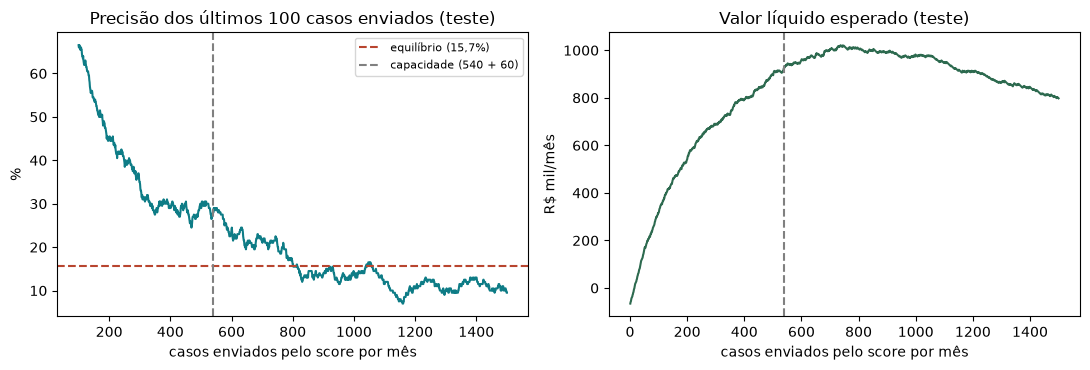

Valor líquido/mês com a capacidade atual: R$ 928.575
Se houvesse capacidade para +100 casos/mês: R$ 44.475/mês a mais


In [8]:
figura, (eixo_precisao, eixo_valor) = plt.subplots(1, 2, figsize=(11, 3.8))
eixo_precisao.plot(curva_teste.index, curva_teste["precisao_marginal"] * 100, color="#0E7C86")
eixo_precisao.axhline(PRECISAO_MARGINAL_EQUILIBRIO * 100, color="#B8452F", ls="--", label="equilíbrio (15,7%)")
eixo_precisao.axvline(ENVIADOS_POR_SCORE_MES, color="gray", ls="--", label="capacidade (540 + 60)")
eixo_precisao.set_xlabel("casos enviados pelo score por mês"); eixo_precisao.set_ylabel("%")
eixo_precisao.set_title("Precisão dos últimos 100 casos enviados (teste)"); eixo_precisao.legend(fontsize=8)

eixo_valor.plot(curva_teste.index, curva_teste["valor_liquido_mes"] / 1e3, color="#2D6A4F")
eixo_valor.axvline(ENVIADOS_POR_SCORE_MES, color="gray", ls="--")
eixo_valor.set_xlabel("casos enviados pelo score por mês"); eixo_valor.set_ylabel("R$ mil/mês")
eixo_valor.set_title("Valor líquido esperado (teste)")
plt.tight_layout(); plt.show()

valor_na_capacidade = curva_teste.loc[ENVIADOS_POR_SCORE_MES, "valor_liquido_mes"]
valor_mais_100 = curva_teste.loc[ENVIADOS_POR_SCORE_MES + 100, "valor_liquido_mes"]
print(f"Valor líquido/mês com a capacidade atual: {formata_brl(valor_na_capacidade)}")
print(f"Se houvesse capacidade para +100 casos/mês: {formata_brl(valor_mais_100 - valor_na_capacidade)}/mês a mais")

**O que concluímos:**
* **A capacidade atual é o gargalo.** Os últimos 100 casos dentro da capacidade ainda acertam **~28%**, bem acima do equilíbrio de 15,7%. Ainda há casos rentáveis ficando de fora.
* **Até onde valeria ampliar:** no teste, a precisão dos últimos 100 casos cruza o equilíbrio **por volta de 800 casos** pelo score, e o valor líquido atinge o máximo (~R$ 1,02 mi/mês) perto de 750. Na validação, o ótimo fica em ~910. Com dois meses de dados por período, a leitura certa é uma **faixa de ~750 a 900 casos**, não um número exato. Perto do topo a curva é plana: errar um pouco para mais ou para menos custa pouco.
* **Valor de ampliar:** +100 casos/mês = **+R$ 44 mil/mês** (~R$ 0,5 mi/ano), já descontado o custo das investigações extras.
* **Ligação com a Parte 1:** realocar parte da capacidade liberada pela pré-análise Auto D0 para a sindicância é uma forma concreta de **converter capacidade em valor** (condição: capacitação dos analistas `[PREMISSA]`).
* O corte deve ser revisto quando mudarem a capacidade, o custo da sindicância, a taxa de irregularidade ou o perfil do score (Parte 6).

> **Em uma frase (Parte 4):** defina o número de casos pelo valor do **próximo** caso; com o modelo novo, os 600 de hoje são pouco, e ampliar para ~750-900 casos pelo score se paga nas premissas usadas.

### Quanto vale trocar de modelo, sem aumentar a capacidade?

Por quê: a Parte 4 olha para a quantidade de casos. Mas a decisão maior é qual
modelo escolher os 540 casos, e ela afeta a priorização do portfólio
(Bloco 1.3). Com a mesma equipe e o mesmo custo de investigação, um modelo que
acerta mais confirma mais irregularidades.

Como o código calcula: confirmações/mês no top 540 do legado contra o modelo
escolhido; a diferença vezes a perda evitada é o ganho. Como as duas premissas
que mais pesam são incertas, a tabela testa metade do ganho de precisão (as
variáveis reais podem ser mais fracas que as simuladas) e metade da perda
evitada.

In [9]:
CUSTO_PROJETO_SINDICANCIA_ANO = 800_000   # [PREMISSA] dados (cruzamento de bases), MLOps e sustentação do modelo novo
meses_no_teste = len(np.unique(mes_teste))

def confirmacoes_por_mes(nome_candidato):
    # irregularidades no top 540 do candidato, convertidas em confirmações esperadas por mês
    return irregular_teste[top540_teste[nome_candidato]].sum() / meses_no_teste * TAXA_CONFIRMACAO_PERICIA

confirmacoes_legado = confirmacoes_por_mes("Modelo legado (hoje)")
confirmacoes_novo = confirmacoes_por_mes(MODELO_ESCOLHIDO)
confirmacoes_adicionais = confirmacoes_novo - confirmacoes_legado
print(f"Mesma capacidade (540 + 60), mesmo custo de investigação:")
print(f"  confirmações/mês - legado: {confirmacoes_legado:.0f} | {MODELO_ESCOLHIDO}: {confirmacoes_novo:.0f} "
      f"| adicionais: {confirmacoes_adicionais:.0f}")

linhas_troca = []
for fracao_do_ganho in (0.5, 1.0):          # e se o ganho real das variáveis for só metade do simulado?
    for perda_evitada in (4_500, PERDA_EVITADA_POR_CONFIRMACAO):  # e se a perda evitada for metade da premissa?
        ganho_bruto_ano = confirmacoes_adicionais * fracao_do_ganho * perda_evitada * 12
        linhas_troca.append({
            "Ganho de precisão que se confirma no histórico": formata_pct(fracao_do_ganho, 0),
            "Perda evitada por confirmação": formata_brl(perda_evitada),
            "Ganho bruto/ano": formata_brl(ganho_bruto_ano),
            "Custo do projeto/ano [PREMISSA]": formata_brl(CUSTO_PROJETO_SINDICANCIA_ANO),
            "Líquido/ano": formata_brl(ganho_bruto_ano - CUSTO_PROJETO_SINDICANCIA_ANO),
        })
pd.DataFrame(linhas_troca)

Mesma capacidade (540 + 60), mesmo custo de investigação:
  confirmações/mês - legado: 89 | ML novas + prompt: 183 | adicionais: 94


,Ganho de precisão que se confirma no histórico,Perda evitada por confirmação,Ganho bruto/ano,Custo do projeto/ano [PREMISSA],Líquido/ano
0,50%,R$ 4.500,R$ 2.535.975,R$ 800.000,R$ 1.735.975
1,50%,R$ 9.000,R$ 5.071.950,R$ 800.000,R$ 4.271.950
2,100%,R$ 4.500,R$ 5.071.950,R$ 800.000,R$ 4.271.950
3,100%,R$ 9.000,R$ 10.143.900,R$ 800.000,R$ 9.343.900


**O que concluímos:**
* Com a mesma capacidade, o modelo novo **dobra as confirmações** (de ~89 para ~183 por mês).
* Nas premissas do notebook, isso vale **~R$ 10 mi/ano brutos**. Mesmo no canto pessimista (metade do ganho e metade da perda evitada), ficam **~R$ 2,5 mi brutos e ~R$ 1,7 mi líquidos**. É comparável à Auto D0 no cenário base, e sem o risco de pagamento automático.
* **Implicação para o portfólio:** a evolução do modelo de sindicância sobe para **co-prioridade 1**. É a maior aposta de valor e também a **validação mais barata**: basta medir o ganho das variáveis novas no histórico real (semanas 1 a 4), antes de qualquer investimento grande.
* **O que pode derrubar a conclusão:** as variáveis novas não terem, nos dados reais, a força que têm no simulador; ou a perda evitada real ser muito menor que R$ 4.500. Por isso o primeiro marco de decisão é esse teste histórico.

> **Em uma frase:** trocar o modelo vale mais que ampliar a capacidade, e possivelmente mais que a própria Auto D0; o primeiro passo é provar o ganho das variáveis novas no histórico.

## Parte 5 — Como medir tudo isso sem conhecer a verdade? (Blocos 3.2 e 4.2)

Por quê: até aqui medimos contra a verdade do simulador, que não existe na vida
real. Esta parte usa só o que a Horizonte teria: os confirmados entre os
investigados e a amostra auditada.

  - Precisão é fácil: os casos enviados são investigados, então a taxa de
    confirmação entre eles é medida diretamente.
  - Recall é difícil: é preciso saber quantas irregularidades ficaram fora do
    top 540. É para isso que serve a auditoria por sorteio: como a probabilidade
    de sorteio é conhecida, cada auditado "representa" 1 ÷ probabilidade
    sinistros do seu estrato (o peso amostral). Com esses pesos se estima o
    total de irregularidades e, daí, o recall.

A tabela compara, para três candidatos, o recall real**, o recall que a equipe
mediria só com os investigados (sem auditoria) e o recall estimado com
auditoria.

In [10]:
investigado_teste = sinistros.loc[teste, "investigado"].to_numpy()
confirmado_teste = sinistros.loc[teste, "confirmado"].to_numpy()
peso_amostral_teste = sinistros.loc[teste, "peso_amostral"].to_numpy()

# Só os investigados entram nas contas (os demais têm peso zero), então o bootstrap só precisa reamostrar esses
indices_investigados = np.flatnonzero(investigado_teste)
pesos_bootstrap_investigados = np.random.default_rng(11).poisson(1.0, size=(1000, len(indices_investigados)))

def estima_recall(selecao, com_peso_amostral):
    peso = peso_amostral_teste[indices_investigados] if com_peso_amostral else np.ones(len(indices_investigados))
    confirmados_ponderados = peso * confirmado_teste[indices_investigados]
    estimativa = (confirmados_ponderados * selecao[indices_investigados]).sum() / confirmados_ponderados.sum()
    reamostras = ((pesos_bootstrap_investigados @ (confirmados_ponderados * selecao[indices_investigados]))
                  / (pesos_bootstrap_investigados @ confirmados_ponderados))
    return estimativa, np.percentile(reamostras, [2.5, 97.5])

linhas_medicao = []
for nome in dict.fromkeys(["Modelo legado (hoje)", "ML variáveis novas", MODELO_ESCOLHIDO]):  # sem repetir
    selecao = top540_teste[nome]
    recall_ingenuo, _ = estima_recall(selecao, com_peso_amostral=False)
    recall_estimado, (ic_inferior, ic_superior) = estima_recall(selecao, com_peso_amostral=True)
    linhas_medicao.append({
        "Candidato": nome,
        "Recall REAL (simulador)": formata_pct(irregular_teste[selecao].sum() / irregular_teste.sum()),
        "Medido só com investigados": formata_pct(recall_ingenuo),
        "Estimado com auditoria": formata_pct(recall_estimado),
        "IC 95% da estimativa": f"[{formata_pct(ic_inferior)}; {formata_pct(ic_superior)}]",
    })
pd.DataFrame(linhas_medicao).set_index("Candidato")

,Recall REAL (simulador),Medido só com investigados,Estimado com auditoria,IC 95% da estimativa
Candidato,,,,
Modelo legado (hoje),"20,5%","96,8%","26,1%","[15,8%; 52,6%]"
ML variáveis novas,"40,2%","41,8%","60,0%","[26,7%; 84,4%]"
ML novas + prompt,"42,1%","42,3%","60,1%","[27,0%; 84,3%]"


**O que concluímos:**
* **Sem auditoria, a medição engana:** o modelo atual "mede" **96,8% de recall** com os próprios rótulos, quando o real é **20,5%**. É o número que a equipe veria hoje, e ele faz o modelo antigo parecer ótimo.
* **Com auditoria, o viés grosseiro some:** a estimativa do legado cai para 26,1%, com IC de 15,8% a 52,6%, que contém o valor real.
* **Mas a precisão é baixa.** Para os modelos novos, a estimativa (60%) erra o real (~41%) por muito, e o IC vai de 27% a 84%. A diferença entre "ML novas" e "ML novas + prompt" (2 pp) é **impossível** de enxergar com esses dados.
* **Por quê:** em dois meses só ~4 confirmações vêm da auditoria, e cada auditado do estrato baixo representa ~800 sinistros (veja a saída da Parte 2). Poucos casos dominam a conta.

**Quanto tempo de auditoria é preciso?** A célula abaixo mede a largura do IC do recall do legado com 2, 4, 8 e 12 meses de auditoria.

In [11]:
# Quanto tempo de auditoria é preciso para medir o recall do legado com precisão razoável?
linhas_janela = []
for meses_de_auditoria in (2, 4, 8, 12):
    janela = (sinistros["mes"] > MESES - meses_de_auditoria) & sinistros["investigado"]
    peso = sinistros.loc[janela, "peso_amostral"].to_numpy()
    confirmados_ponderados = peso * sinistros.loc[janela, "confirmado"].to_numpy()
    no_top_legado = sinistros.loc[janela, "enviado_pelo_score"].to_numpy()
    reamostras_pesos = np.random.default_rng(13).poisson(1.0, size=(1000, int(janela.sum())))
    reamostras = (reamostras_pesos @ (confirmados_ponderados * no_top_legado)) / (reamostras_pesos @ confirmados_ponderados)
    ic_inferior, ic_superior = np.percentile(reamostras, [2.5, 97.5])
    verdade = sinistros.loc[sinistros["mes"] > MESES - meses_de_auditoria]
    linhas_janela.append({
        "Meses de auditoria": meses_de_auditoria,
        "Casos auditados": AUDITORIA_MES * meses_de_auditoria,
        "Recall real do legado": formata_pct(verdade.loc[verdade["enviado_pelo_score"], "irregular"].sum() / verdade["irregular"].sum()),
        "Estimado": formata_pct((confirmados_ponderados * no_top_legado).sum() / confirmados_ponderados.sum()),
        "IC 95%": f"[{formata_pct(ic_inferior)}; {formata_pct(ic_superior)}]",
        "Largura do IC": formata_pp(ic_superior - ic_inferior).replace("+", ""),
    })
pd.DataFrame(linhas_janela).set_index("Meses de auditoria")

,Casos auditados,Recall real do legado,Estimado,IC 95%,Largura do IC
Meses de auditoria,,,,,
2,120,"20,5%","26,1%","[15,7%; 65,9%]","50,2 pp"
4,240,"20,0%","33,7%","[22,6%; 58,2%]","35,7 pp"
8,480,"20,6%","25,1%","[14,6%; 46,7%]","32,2 pp"
12,720,"20,9%","26,3%","[17,2%; 40,0%]","22,7 pp"


**O que concluímos:**
* Mesmo com **12 meses** (720 casos auditados), o IC ainda tem ~23 pp de largura, e as estimativas tendem a ficar **acima** do real: com poucos positivos auditados, o estimador subestima o total de irregularidades. A auditoria custa **60 × R$ 1.200 = R$ 72 mil/mês**; é o preço de medir.

**Decisões de desenho que saem daqui:**
1. **A auditoria serve para detectar viés grosseiro e mudança de cenário**, não para comparar modelos parecidos.
2. **Para escolher entre modelos, usar champion/challenger**: reservar parte da capacidade para os casos que só o modelo desafiante enviaria. Como **precisão se mede diretamente**, a comparação fica rápida e sem viés.
3. **Se for preciso conhecer o recall com mais precisão**, ampliar a auditoria por um período curto (ex.: 120/mês nos três primeiros meses) e revisar a divisão entre os estratos.

> **Em uma frase (Parte 5):** precisão se mede nos investigados; recall só com auditoria por sorteio, que corrige o viés mas é imprecisa. Compare modelos por *champion/challenger*, não por recall estimado.

## Parte 6 — Como perceber que o modelo degradou? (Bloco 3.3)

Por quê: a fraude muda, os dados mudam e o modelo envelhece. O monitoramento
precisa dizer quando agir, com limites definidos antes.

| O que acompanhar                     | Como                                                                                                                          |
| ------------------------------------ | ----------------------------------------------------------------------------------------------------------------------------- |
| Os dados e o score mudaram?          | **PSI** do score (calculado abaixo) e das principais variáveis                                                                |
| O modelo continua acertando?         | **Precisão** nos casos investigados, por faixa de score (medida direta)                                                       |
| Há irregularidade escapando?         | **Recall estimado com a auditoria** (Parte 5): tendência ao longo de meses, não mês a mês                                     |
| O analista confia?                   | Taxa de **override** (o analista contraria a recomendação)                                                                    |
| O agente de pré-análise está seguro? | Concordância com a decisão final, **falso-OK na auditoria por amostragem**, regras bloqueantes disparadas, custo por sinistro |

Abaixo, o PSI em três situações: dois meses normais e um mês com mudança
simulada (mais acionamentos de guincho e mais cotações, como uma nova modalidade
de fraude).

In [12]:
def indice_estabilidade_populacional(distribuicao_referencia, distribuicao_atual, faixas=10):
    # PSI: compara a proporção de casos em cada faixa (decis da referência) entre dois períodos
    limites = np.quantile(distribuicao_referencia, np.linspace(0, 1, faixas + 1))
    limites[0], limites[-1] = -np.inf, np.inf
    proporcao_referencia = np.histogram(distribuicao_referencia, limites)[0] / len(distribuicao_referencia)
    proporcao_atual = np.histogram(distribuicao_atual, limites)[0] / len(distribuicao_atual)
    proporcao_referencia, proporcao_atual = np.clip(proporcao_referencia, 1e-4, None), np.clip(proporcao_atual, 1e-4, None)
    return float(np.sum((proporcao_atual - proporcao_referencia) * np.log(proporcao_atual / proporcao_referencia)))

variaveis_escolhidas, modelo_escolhido = MODELOS_ML[MODELO_ESCOLHIDO]
score_referencia = modelo_escolhido.predict_proba(sinistros.loc[validacao, variaveis_escolhidas])[:, 1]
sinistros_mes_12 = sinistros[sinistros["mes"] == 12]

# Mês 12 com mudança simulada: +35% de acionamentos de guincho e +1 cotação por cliente (ex.: nova modalidade de fraude)
sinistros_com_mudanca = sinistros_mes_12.copy()
sinistros_com_mudanca["guincho_antes_evento"] = (sinistros_com_mudanca["guincho_antes_evento"].astype(bool)
                                                | (np.random.default_rng(3).random(len(sinistros_com_mudanca)) < 0.35)).astype(int)
sinistros_com_mudanca["cotacoes_90d"] = sinistros_com_mudanca["cotacoes_90d"] + 1

for rotulo, periodo in [("mês 11 (normal)", sinistros[sinistros["mes"] == 11]),
                       ("mês 12 (normal)", sinistros_mes_12),
                       ("mês 12 com mudança simulada", sinistros_com_mudanca)]:
    psi = indice_estabilidade_populacional(score_referencia, modelo_escolhido.predict_proba(periodo[variaveis_escolhidas])[:, 1])
    print(f"PSI do score, {rotulo:30s}: {psi:.3f}".replace(".", ","))
print("Regra de bolso: abaixo de 0,10 estável - 0,10 a 0,25 atenção - acima de 0,25 ação")

PSI do score, mês 11 (normal)               : 0,001
PSI do score, mês 12 (normal)               : 0,000
PSI do score, mês 12 com mudança simulada   : 0,804
Regra de bolso: abaixo de 0,10 estável - 0,10 a 0,25 atenção - acima de 0,25 ação


**O que concluímos:** nos meses normais o PSI fica perto de zero. No mês com mudança, sobe para ~0,88, **muito acima do limite de ação (0,25)**: o alerta dispararia e o modelo seria reavaliado (e o ponto de corte da Parte 4 também).

> **Em uma frase (Parte 6):** monitore estabilidade do score (PSI), precisão nos investigados e **override**, com responsáveis e limites definidos antes de ir para produção.

## Parte 7 — Aprofundamento: três armadilhas do ML de fraude (Bloco 3.2)

Opcional numa primeira leitura. Explica três decisões técnicas do desenho, que
costumam ser questionadas na arguição.

### 7.1 Que rótulo usar no treino?

Só os investigados têm rótulo. Há três saídas comuns; todas foram treinadas com
as variáveis novas:

  - Só investigados, sem peso: usar apenas quem tem rótulo (a escolhida nas
    Partes 3 a 6).
  - Ingênua: tratar todo não investigado como "não irregular". É o erro mais
    comum.
  - IPW (peso amostral): usar os investigados, dando a cada auditado o peso 1 ÷
    probabilidade de sorteio, para representar a base inteira.

Duas perguntas diferentes: qual ordena melhor (precisão no top 540)? E qual dá
uma probabilidade confiável (a média prevista bate com a taxa real)?

In [13]:
taxa_confirmavel_teste = irregular_teste.mean() * TAXA_CONFIRMACAO_PERICIA  # o que um modelo de "confirmado" deveria prever, em média
ESTRATEGIAS_ROTULO = {
    "Só investigados, sem peso (usada nas Partes 3 a 6)": dict(filtro=treino_investigados, pesos=None),
    "Ingênua: não investigado = não irregular":          dict(filtro=treino, pesos=None),
    "Investigados com peso amostral (IPW)":               dict(filtro=treino_investigados,
                                                              pesos=sinistros.loc[treino_investigados, "peso_amostral"]),
}
linhas_rotulo = []
for nome_estrategia, configuracao in ESTRATEGIAS_ROTULO.items():
    modelo = treina_modelo(VARIAVEIS_NOVAS, configuracao["filtro"], pesos=configuracao["pesos"])
    probabilidade_validacao = modelo.predict_proba(sinistros.loc[validacao, VARIAVEIS_NOVAS])[:, 1]
    probabilidade_teste = modelo.predict_proba(sinistros.loc[teste, VARIAVEIS_NOVAS])[:, 1]
    linhas_rotulo.append({
        "Estratégia de rótulo": nome_estrategia,
        "Precisão validação": formata_pct(irregular_validacao[seleciona_top_por_mes(probabilidade_validacao, mes_validacao, ENVIADOS_POR_SCORE_MES)].mean()),
        "Precisão teste": formata_pct(irregular_teste[seleciona_top_por_mes(probabilidade_teste, mes_teste, ENVIADOS_POR_SCORE_MES)].mean()),
        "Probabilidade média prevista": formata_pct(probabilidade_teste.mean(), 2),
        "Taxa real confirmável": formata_pct(taxa_confirmavel_teste, 2),
    })
pd.DataFrame(linhas_rotulo).set_index("Estratégia de rótulo")

,Precisão validação,Precisão teste,Probabilidade média prevista,Taxa real confirmável
Estratégia de rótulo,,,,
"Só investigados, sem peso (usada nas Partes 3 a 6)","39,0%","38,1%","5,74%","2,18%"
Ingênua: não investigado = não irregular,"30,9%","30,4%","0,46%","2,18%"
Investigados com peso amostral (IPW),"32,8%","34,6%","2,08%","2,18%"


**O que concluímos:**
* **Para ordenar, "só investigados" é a melhor:** 38% de precisão contra 35% do IPW e 30% da ingênua.
* **Mas ela superestima a probabilidade:** prevê 5,7% em média, contra 2,2% reais, porque aprendeu onde a taxa é ~16%. **O IPW acerta a probabilidade** (2,1%), porque representa a base inteira. A ingênua erra as duas coisas.
* **Recomendação:** ordenar com o modelo "só investigados" e, quando a probabilidade for usada para decidir (valor esperado, faixas de risco), **recalibrá-la com a amostra auditada**.

### 7.2 Vazamento de dados: o laudo

O laudo da sindicância só existe depois da investigação. Se ele entrar no
treino, o modelo parece excelente na validação, mas não funciona em produção,
porque no momento do score (D0) o laudo não existe. Para não contaminar o teste,
a validação usa só os meses 9 e 10.

In [14]:
# O laudo só existe DEPOIS da sindicância. Aqui ele é (indevidamente) usado como variável.
gerador_laudo = np.random.default_rng(SEMENTE + 2)
investigados = sinistros[sinistros["investigado"]].copy()
investigados["laudo_conclusivo"] = np.where(investigados["irregular"] == 1,
                                            gerador_laudo.random(len(investigados)) < 0.90,
                                            gerador_laudo.random(len(investigados)) < 0.02).astype(int)

treino_laudo = investigados["mes"] <= 8
validacao_laudo = investigados["mes"].isin([9, 10])  # meses 11-12 ficam intocados (são o teste)
for descricao, variaveis in [("sem vazamento", VARIAVEIS_NOVAS), ("COM vazamento (+ laudo)", VARIAVEIS_NOVAS + ["laudo_conclusivo"])]:
    modelo = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.06, max_iter=250, l2_regularization=1.0,
                                            random_state=SEMENTE).fit(investigados.loc[treino_laudo, variaveis],
                                                                     investigados.loc[treino_laudo, "confirmado"])
    probabilidade = modelo.predict_proba(investigados.loc[validacao_laudo, variaveis])[:, 1]
    pr_auc = average_precision_score(investigados.loc[validacao_laudo, "confirmado"], probabilidade)
    print(f"{descricao:25s} PR-AUC na validação: {pr_auc:.3f}".replace(".", ","))
print("-> o salto é artificial: quando o score é calculado (D0), o laudo ainda não existe.")

sem vazamento             PR-AUC na validação: 0,475


COM vazamento (+ laudo)   PR-AUC na validação: 0,712
-> o salto é artificial: quando o score é calculado (D0), o laudo ainda não existe.


**O que concluímos:** o PR-AUC salta de ~0,48 para ~0,71 **de forma artificial**.

**Regra de prevenção:** toda variável precisa de uma **data de disponibilidade** e só entra se já existia no D0. Para "guincho antes do evento", a janela é anterior à **data da ocorrência** (e não à do aviso). Quando as chaves de cotação, emissão e assistência não casam, o cruzamento deve respeitar a data (*point-in-time join*).

### 7.3 Desbalanceamento: só ~2,5% dos sinistros são irregulares

Para escolher o top 540 o que importa é a ordem. Técnicas de balanceamento
(aqui, class_weight="balanced"; SMOTE tem o mesmo efeito) não melhoram a ordem e
distorcem a probabilidade.

In [15]:
linhas_balanceamento = []
for class_weight in (None, "balanced"):
    modelo = treina_modelo(variaveis_escolhidas, treino_investigados, class_weight=class_weight)
    probabilidade_teste = modelo.predict_proba(sinistros.loc[teste, variaveis_escolhidas])[:, 1]
    linhas_balanceamento.append({
        "class_weight": str(class_weight),
        "Precisão (top 540)": formata_pct(irregular_teste[seleciona_top_por_mes(probabilidade_teste, mes_teste, ENVIADOS_POR_SCORE_MES)].mean()),
        "PR-AUC": f"{average_precision_score(irregular_teste, probabilidade_teste):.3f}".replace(".", ","),
        "Probabilidade média prevista": formata_pct(probabilidade_teste.mean(), 2),
        "Taxa real confirmável": formata_pct(taxa_confirmavel_teste, 2),
    })
pd.DataFrame(linhas_balanceamento).set_index("class_weight")

,Precisão (top 540),PR-AUC,Probabilidade média prevista,Taxa real confirmável
class_weight,,,,
None,"39,9%","0,372","5,34%","2,18%"
balanced,"40,0%","0,372","14,14%","2,18%"


**O que concluímos:** a precisão e o PR-AUC ficam iguais, mas a probabilidade média prevista sobe de 5,3% para **14,1%** (a real é 2,2%). Balancear não ajuda a ordenar e piora a calibração.

> **Em uma frase (Parte 7):** treine com os investigados e recalibre com a auditoria; só use variáveis que existiam no D0; não balanceie para "consertar" a raridade da fraude.

## Parte 8 — Conclusões, grau de confiança e limites

### Conclusões

| \# | Conclusão                                                                                                                                | Evidência                                                                | Confiança                                                             | O que mudaria a conclusão                                                |
| -- | ---------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------ | --------------------------------------------------------------------- | ------------------------------------------------------------------------ |
| 1  | A pré-análise Auto D0 só se paga se **\~52% da capacidade liberada virar caixa** ou valor equivalente                                    | Parte 1 (aritmética sobre premissas)                                     | **Alta** na lógica; números dependem das premissas                    | Custo/hora, % elegível ao fluxo direto, custo fixo real                  |
| 2  | O fluxo direto só pode abrir com **pagamento indevido adicional \< \~0,2%**, medido em *shadow mode*                                     | Parte 1                                                                  | **Alta** na lógica                                                    | Indenização média e % no fluxo direto                                    |
| 3  | O agente de vidro **não se paga por custo**; só por prazo e experiência                                                                  | Parte 1 (números do enunciado + custo marginal \[PREMISSA\])             | **Média**                                                             | Custo marginal real; valor atribuído ao prazo de pagamento               |
| 4  | As **variáveis novas** são a maior alavanca do modelo de sindicância                                                                     | Parte 3 (+27,6 pp, IC longe de zero)                                     | **Média**: robusto no simulador, mas a força das variáveis é premissa | Primeira análise com dados reais (Bloco 4)                               |
| 5  | Retreinar com as mesmas variáveis e os rótulos do legado **não resolve**                                                                 | Parte 3 (-8,9 pp)                                                        | **Média**                                                             | Se o legado não tiver vantagem de triagem humana                         |
| 6  | O prompt **não substitui** o ML; como variável, agrega **pouco e só se tiver informação própria**                                        | Parte 3 (+1,8 pp; versão redundante não agrega)                          | **Baixa**: resultado depende da premissa                              | Teste histórico com a versão congelada do prompt                         |
| 7  | Com o modelo novo, **a capacidade de 600 é o gargalo**; ampliar se paga                                                                  | Parte 4 (precisão marginal 28% \> 15,7%)                                 | **Média**                                                             | Custo de sindicância, perda evitada e precisão real                      |
| 7b | **Trocar o modelo vale mais que ampliar a capacidade** e justifica a sindicância v2 como co-prioridade 1                                 | Parte 4 (confirmações dobram; \~R$ 2,5 mi/ano mesmo no canto pessimista) | **Média**                                                             | Força real das variáveis novas no histórico (é o primeiro teste a fazer) |
| 8  | **Sem auditoria a medição engana** (recall de 97% "medido" × 20% real); com 60/mês ela corrige o viés, mas não compara modelos parecidos | Parte 5                                                                  | **Alta** (é estatística, não premissa de negócio)                     | Tamanho e divisão da amostra de auditoria                                |
| 9  | Treinar com investigados e **recalibrar com a auditoria**; **não** usar variáveis pós-D0; **não** balancear                              | Parte 7                                                                  | **Alta** (prática consolidada, confirmada no simulador)               | —                                                                        |

### O que este notebook não prova

1.  Os números de ML são consequência do simulador. O que se transfere para a
    vida real é o protocolo: mesmo teste, mesmo número de casos, corte temporal,
    IC pareado, auditoria por sorteio e champion/challenger.
2.  O score do prompt é uma abstração. Na vida real o prompt não é
    determinístico, não tem versão nem log, e cada analista tem sua cópia. O
    primeiro passo é congelar uma versão e medir a variação entre execuções.
3.  As cifras [PREMISSA] precisam de dados reais: % elegível ao fluxo direto,
    custo/hora, indenização média, custo da sindicância, perda evitada, taxa de
    irregularidade, custo marginal do vidro.
4.  Não simulamos a reação do fraudador: quando o critério fica conhecido, o
    comportamento muda. Por isso o monitoramento e a revisão periódica do corte.
5.  A reamostragem do IC mantém fixo o top 540 de cada modelo. É uma aproximação
    que ignora a incerteza de quais casos entrariam no top, então os intervalos
    são ligeiramente otimistas.